In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

from forecast import baselines
from forecast.data import load_visits
from forecast.metrics import mae, rmse, rmsle
from forecast.validation import time_split

FIG = Path("../reports/figures")
FIG.mkdir(parents=True, exist_ok=True)

visits = load_visits()
train, valid, cutoff = time_split(visits)

methods = {
    "global median": baselines.global_median,
    "naive (last value)": baselines.naive_last_value,
    "store median": baselines.store_median,
    "store log-mean": baselines.store_log_mean,
    "store x weekday log-mean": baselines.store_weekday_log_mean,
    "seasonal naive (last same weekday)": baselines.seasonal_naive,
    "mean of last 4 same weekdays": baselines.last_same_weekdays_mean,
}

rows = []
for name, predict in methods.items():
    pred = predict(train, valid)
    rows.append(
        {
            "method": name,
            "RMSLE": rmsle(valid["visitors"], pred),
            "MAE": mae(valid["visitors"], pred),
            "RMSE": rmse(valid["visitors"], pred),
        }
    )

scoreboard = pd.DataFrame(rows).set_index("method")
reference = scoreboard.loc["store median", "RMSLE"]
scoreboard["RMSLE vs store median (%)"] = (1 - scoreboard["RMSLE"] / reference) * 100
print(scoreboard.round(3))

                                    RMSLE     MAE    RMSE  \
method                                                      
global median                       0.833  13.048  19.108   
naive (last value)                  0.838  11.835  21.536   
store median                        0.624   9.113  14.593   
store log-mean                      0.622   9.369  15.024   
store x weekday log-mean            0.551   7.859  13.084   
seasonal naive (last same weekday)  0.676   9.564  19.601   
mean of last 4 same weekdays        0.573   7.907  12.981   

                                    RMSLE vs store median (%)  
method                                                         
global median                                         -33.487  
naive (last value)                                    -34.341  
store median                                            0.000  
store log-mean                                          0.382  
store x weekday log-mean                               11.708  
se

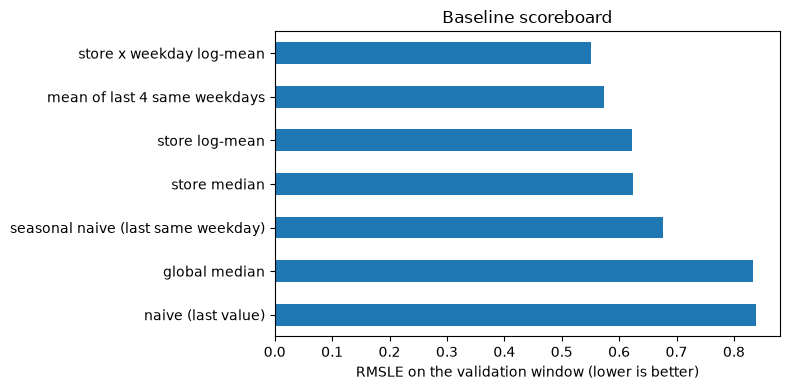

In [2]:
fig, ax = plt.subplots(figsize=(8, 4))
scoreboard["RMSLE"].sort_values(ascending=False).plot.barh(ax=ax)
ax.set_xlabel("RMSLE on the validation window (lower is better)")
ax.set_ylabel("")
ax.set_title("Baseline scoreboard")
fig.tight_layout()
fig.savefig(FIG / "baseline_scoreboard.png", dpi=120)
plt.show()

## Key findings
1. Scoreboard: the best baseline on RMSLE is store x weekday log-mean (0.551), 11.7% better than the store median (0.624). This is the score a model has to beat.
2. Naive and the global median are the weakest (about 0.83 RMSLE): the global median gives every store the same number and ignores store size, and naive repeats one single day's value for all 39 days.
3. Averaging helps: the last same weekday alone scores 0.676, the mean of the last 4 same weekdays 0.573, and the full weekday history 0.551, because averaging multiple observations reduces the effect of unusual daily fluctuations.
4. The metric decides the winner: the store log-mean beats the store median on RMSLE (0.622 vs 0.624) but loses on MAE (9.369 vs 9.113), as expected because RMSLE focuses on relative errors while MAE measures absolute errors.
5. Limitation: the validation window has only 1 holiday day out of 39, while the test window has 4. These baselines know weekdays but not holidays, so the validation score may look better than the real test score, and holidays need their own handling in the model.